In [2]:
import os
import re
from collections import defaultdict
import sys
sys.path.append('..')
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from cmap import Colormap

mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

sensor_colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

# Alcohol

In [4]:
# alcohol_data_dir = '../data/blood_alcohol_spectra/'
# files = os.listdir(alcohol_data_dir)

# # Filter for files matching the pattern 0_xx_alc_slide.csv (with the '1' suffix)
# pattern = r'^0_(\d{2})_alc_slide1\.csv$'
# filtered_files = []
# alcohol_concentrations = []

# for file in files:
#     match = re.match(pattern, file)
#     if match:
#         filtered_files.append(file)
#         # Extract the two digits and convert to decimal
#         digits = match.group(1)
#         concentration = float(f"0.{digits}")
#         alcohol_concentrations.append(concentration)

# # Sort both lists by concentration
# sorted_pairs = sorted(zip(alcohol_concentrations, filtered_files))
# alcohol_concentrations = [pair[0] for pair in sorted_pairs]
# filtered_files = [pair[1] for pair in sorted_pairs]

# print("Filtered filenames:")
# for file in filtered_files:
#     print(f"  {file}")

# print(f"\nCorresponding alcohol concentrations:")
# for conc in alcohol_concentrations:
#     print(f"  {conc}")

# print(f"\nTotal files found: {len(filtered_files)}")

In [5]:
# # plot raw data
# plt.figure(figsize=(6, 4))
# for i, file in enumerate(filtered_files):
#     data = pd.read_csv(os.path.join(alcohol_data_dir, file), skiprows=9, header=None)
#     wavelength = data.iloc[:, 0].values
#     intensity = data.iloc[:, 1].values

#     plt.plot(wavelength, intensity + i * 1, color=sensor_colors[i % len(sensor_colors)], label=f'{alcohol_concentrations[i]:.2f} BAC')

# Alcohol new

In [6]:
alcohol_data_dir = '../data/blood_alcohol_spectra_2/'
files = os.listdir(alcohol_data_dir)
files

['0_00_alc_3size_20scans_8ms_opt_1.csv',
 '0_00_alc_3size_20scans_8ms_opt_2.csv',
 '0_00_alc_3size_20scans_8ms_opt_3.csv',
 '0_00_alc_3size_20scans_8ms_opt_4.csv',
 '0_00_alc_3size_20scans_8ms_opt_5.csv',
 '0_02_alc_3size_20scans_8ms_opt_1.csv',
 '0_02_alc_3size_20scans_8ms_opt_2.csv',
 '0_02_alc_3size_20scans_8ms_opt_3.csv',
 '0_02_alc_3size_20scans_8ms_opt_4.csv',
 '0_02_alc_3size_20scans_8ms_opt_5.csv',
 '0_05_alc_3size_20scans_8ms_opt_1.csv',
 '0_05_alc_3size_20scans_8ms_opt_2.csv',
 '0_05_alc_3size_20scans_8ms_opt_3.csv',
 '0_05_alc_3size_20scans_8ms_opt_4.csv',
 '0_05_alc_3size_20scans_8ms_opt_5.csv',
 '0_08_alc_3size_20scans_8ms_opt_1.csv',
 '0_08_alc_3size_20scans_8ms_opt_2.csv',
 '0_08_alc_3size_20scans_8ms_opt_3.csv',
 '0_08_alc_3size_20scans_8ms_opt_4.csv',
 '0_08_alc_3size_20scans_8ms_opt_5.csv',
 '0_10_alc_3size_20scans_8ms_opt_1.csv',
 '0_10_alc_3size_20scans_8ms_opt_2.csv',
 '0_10_alc_3size_20scans_8ms_opt_3.csv',
 '0_10_alc_3size_20scans_8ms_opt_4.csv',
 '0_10_alc_3size

In [7]:
def calculate_average_spectrum(file_list, data_dir):
    all_spectra = []
    wavelength = None
    
    for file in file_list:
        file_path = os.path.join(data_dir, file)
        data = pd.read_csv(file_path, skiprows=9, header=None, names=['wavelength', 'absorbance'])
        if wavelength is None:
            wavelength = data['wavelength'].values
        all_spectra.append(data['absorbance'].values)
    
    avg_spectrum = np.mean(all_spectra, axis=0)
    return pd.DataFrame({'wavelength': wavelength, 'absorbance': avg_spectrum})

In [8]:
# Group files by concentration pattern
concentration_groups = defaultdict(list)

for file in files:
    # Extract concentration from filename pattern x_xx_alc_*
    match = re.match(r'^(\d+)_(\d{2})_alc_', file)
    if match and file.endswith('.csv'):
        # Convert to decimal concentration (e.g., 0_08 -> 0.08)
        whole_part = int(match.group(1))
        decimal_part = int(match.group(2))
        concentration = float(f"{whole_part}.{decimal_part:02d}")
        concentration_groups[concentration].append(file)

# Calculate averages for each concentration group
alcohol_avg_data_new = {}
for concentration in sorted(concentration_groups.keys()):
    file_list = concentration_groups[concentration]
    print(f"Concentration {concentration:.2f}%: {len(file_list)} files")
    for file in file_list:
        print(f"  {file}")
    
    avg_data = calculate_average_spectrum(file_list, alcohol_data_dir)
    alcohol_avg_data_new[concentration] = avg_data

print(f"\nProcessed {len(alcohol_avg_data_new)} concentration groups:")
for conc in sorted(alcohol_avg_data_new.keys()):
    print(f"  {conc:.2f}% alcohol (averaged over {len(concentration_groups[conc])} files)")

Concentration 0.00%: 5 files
  0_00_alc_3size_20scans_8ms_opt_1.csv
  0_00_alc_3size_20scans_8ms_opt_2.csv
  0_00_alc_3size_20scans_8ms_opt_3.csv
  0_00_alc_3size_20scans_8ms_opt_4.csv
  0_00_alc_3size_20scans_8ms_opt_5.csv
Concentration 0.02%: 5 files
  0_02_alc_3size_20scans_8ms_opt_1.csv
  0_02_alc_3size_20scans_8ms_opt_2.csv
  0_02_alc_3size_20scans_8ms_opt_3.csv
  0_02_alc_3size_20scans_8ms_opt_4.csv
  0_02_alc_3size_20scans_8ms_opt_5.csv
Concentration 0.05%: 5 files
  0_05_alc_3size_20scans_8ms_opt_1.csv
  0_05_alc_3size_20scans_8ms_opt_2.csv
  0_05_alc_3size_20scans_8ms_opt_3.csv
  0_05_alc_3size_20scans_8ms_opt_4.csv
  0_05_alc_3size_20scans_8ms_opt_5.csv
Concentration 0.08%: 5 files
  0_08_alc_3size_20scans_8ms_opt_1.csv
  0_08_alc_3size_20scans_8ms_opt_2.csv
  0_08_alc_3size_20scans_8ms_opt_3.csv
  0_08_alc_3size_20scans_8ms_opt_4.csv
  0_08_alc_3size_20scans_8ms_opt_5.csv
Concentration 0.10%: 5 files
  0_10_alc_3size_20scans_8ms_opt_1.csv
  0_10_alc_3size_20scans_8ms_opt_2.c

# Acetaldehyde

In [9]:
acetaldehyde_data_dir = '../data/blood_acetaldehyde_spectra/'
files = os.listdir(acetaldehyde_data_dir)

# Group acetaldehyde files by concentration
aceta_0_02_files = [f for f in files if f.startswith('aceta_0_02_window_size1_')]
aceta_0_40_files = [f for f in files if f.startswith('aceta_0_40_window_size1_')]

# Calculate averages for each concentration group
acetaldehyde_avg_data = {
    0.02: calculate_average_spectrum(aceta_0_02_files, acetaldehyde_data_dir),
    0.40: calculate_average_spectrum(aceta_0_40_files, acetaldehyde_data_dir)
}

# Combine data

In [110]:
# Extract alcohol concentrations and create file mappings from new data
alcohol_concentrations = sorted(alcohol_avg_data_new.keys())
filtered_files = [f'alcohol_avg_{conc:.2f}' for conc in alcohol_concentrations]

# Combine alcohol and acetaldehyde data
all_concentrations = alcohol_concentrations + [0.02, 0.40]
all_files = filtered_files + ['acetaldehyde_0_02_avg', 'acetaldehyde_0_40_avg']

# Sort by concentration
sorted_pairs = sorted(zip(all_concentrations, all_files))
all_concentrations = [pair[0] for pair in sorted_pairs]
all_files = [pair[1] for pair in sorted_pairs]

# Load and preprocess all data before plotting
processed_data = []
for i, file in enumerate(all_files):
    if file.startswith('acetaldehyde_'):
        # Handle averaged acetaldehyde data
        concentration = all_concentrations[i]
        data = acetaldehyde_avg_data[concentration]
    elif file.startswith('alcohol_avg_'):
        # Handle new alcohol averaged data
        concentration = all_concentrations[i]
        data = alcohol_avg_data_new[concentration]
    else:
        # Handle old alcohol files (fallback, shouldn't be used)
        file_path = os.path.join(alcohol_data_dir, file)
        data = pd.read_csv(file_path, skiprows=9, header=None, names=['wavelength', 'absorbance'])
    
    log_absorbance = np.log(data['absorbance'] + 1e-6)  # Avoid log(0)
    log_absorbance = savgol_filter(log_absorbance, window_length=91, polyorder=3)
    processed_data.append({'wavelength': data['wavelength'], 'log_absorbance': log_absorbance})

# find the wavelength array and the absorbance array of the median spectrum
S = np.vstack([d['log_absorbance'] for d in processed_data])                    # [N, L]
w = np.median(np.vstack([d['wavelength'] for d in processed_data]), axis=0)     # [L]

keep = (w >= 410) & (w <= 950)
w = w[keep]
S = S[:, keep]
r = np.median(S, axis=0)

X = np.vstack([np.ones_like(w), w, w**2, r]).T      # [L, 4]
XtX_inv = np.linalg.pinv(X.T @ X)                   # precompute for efficiency
Xt = X.T

S_emsc = np.empty_like(S)
for i, s in enumerate(S):
    a = XtX_inv @ Xt @ s
    S_emsc[i] = (s - (a[0] + a[1]*w + a[2]*w**2)) / (a[3] if a[3]!=0 else 1.0)

# For Fig2

## processed spectra

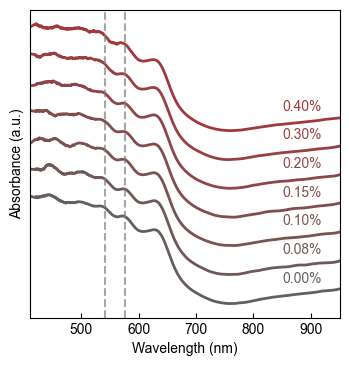

In [134]:
cm = Colormap(['#655e5c', '#c92127'])
colors = cm(np.linspace(0, 1, len(all_files)))

# Define unique colors for acetaldehyde data
acetaldehyde_colors = ['#183999', '#265cff']

exclude_concentrations = [0.02, 0.05]  # Exclude 0.02% and 0.05% alcohol concentrations

# Apply exclusions based on concentration values
included_indices = []
for i in range(len(all_files)):
    concentration = all_concentrations[i]
    # Only exclude if it's an alcohol concentration (not acetaldehyde) and in exclude list
    if all_files[i].startswith('alcohol_avg_') and concentration in exclude_concentrations:
        continue  # Skip this one
    else:
        included_indices.append(i)

y_offset = 0.8

plt.figure(figsize=(4, 4))

# Separate and sort alcohol and acetaldehyde indices from included data
alcohol_indices = [i for i in included_indices if not all_files[i].startswith('acetaldehyde_')]
acetaldehyde_indices = [i for i in included_indices if all_files[i].startswith('acetaldehyde_')]

# Sort alcohol indices by concentration (ascending)
alcohol_indices.sort(key=lambda x: all_concentrations[x])
# Sort acetaldehyde indices by concentration (ascending)
acetaldehyde_indices.sort(key=lambda x: all_concentrations[x])

# Plot alcohol data first (bottom to top: 0.00, 0.02, 0.05, ..., 0.40)
for plot_idx, i in enumerate(alcohol_indices):
    s = S_emsc[i]
    concentration = all_concentrations[i]
    color = colors[plot_idx % len(colors)]
    
    plt.plot(w, s + plot_idx * y_offset, 
             color=color, linewidth=2)
    
    # Add text label for alcohol concentration
    plt.text(850, s[np.argmin(np.abs(w - 850))] + plot_idx * y_offset + 0.5, 
             f'{concentration:.2f}%', 
             fontsize=10, color=color, ha='left', va='center')

# Plot acetaldehyde data on top (0.02 acetaldehyde, 0.40 acetaldehyde)
# for plot_idx, i in enumerate(acetaldehyde_indices):
#     s = S_emsc[i]
#     concentration = all_concentrations[i]
#     color = acetaldehyde_colors[plot_idx % len(acetaldehyde_colors)]
#     label = f'{concentration:.2f}% acetaldehyde (avg)'
    
#     # Place acetaldehyde above all alcohol data
#     plt.plot(w, s + (len(alcohol_indices) + plot_idx) * y_offset, 
#              color=color, linewidth=2, 
#              label=label)

plt.axvline(x=542, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
plt.axvline(x=577, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Absorbance (a.u.)')
plt.yticks([])

plt.xlim(410, 950)
plt.tick_params(direction='in')

# save the current axis position for reproducing later
pos_ax = plt.gca().get_position()

plt.savefig('../figures/fig2/blood_alcohol_spectra_new.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

## peak analysis

In [117]:
# peak_analysis_data_path = '../figures/fig2/unified_reference_trends.csv'
# peak_analysis_df = pd.read_csv(peak_analysis_data_path)
# print("\nPeak analysis data:")
# print(peak_analysis_df.head())

In [118]:
# # Examine the complete dataset and calculate trend lines
# print("Complete peak analysis data:")
# print(peak_analysis_df)
# print(f"\nDataset shape: {peak_analysis_df.shape}")
# print(f"Columns: {list(peak_analysis_df.columns)}")
# print(f"\nUnique series: {peak_analysis_df['series'].unique()}")

# # Separate alcohol and acetaldehyde data
# alcohol_data = peak_analysis_df[peak_analysis_df['series'] == 'alcohol'].copy()
# acetaldehyde_data = peak_analysis_df[peak_analysis_df['series'] == 'acetaldehyde'].copy()

# print(f"\nAlcohol data points: {len(alcohol_data)}")
# print(f"Acetaldehyde data points: {len(acetaldehyde_data)}")

# # Get the last three columns for trend analysis
# relative_cols = peak_analysis_df.columns[-3:].tolist()
# print(f"\nColumns for trend analysis: {relative_cols}")

# # Calculate linear trend lines for each column
# from scipy import stats
# import numpy as np

# trend_data = {}

# # For alcohol data
# for col in relative_cols:
#     if len(alcohol_data) > 1:
#         x = alcohol_data['concentration_%'].values
#         y = alcohol_data[col].values
#         slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
#         trend_data[f'alcohol_{col}'] = {
#             'slope': slope,
#             'intercept': intercept,
#             'r_squared': r_value**2,
#             'x_data': x,
#             'y_data': y
#         }
#         print(f"\nAlcohol {col}:")
#         print(f"  Slope: {slope:.6f}")
#         print(f"  Intercept: {intercept:.6f}")
#         print(f"  R²: {r_value**2:.6f}")

# # For acetaldehyde data
# for col in relative_cols:
#     if len(acetaldehyde_data) > 1:
#         x = acetaldehyde_data['concentration_%'].values
#         y = acetaldehyde_data[col].values
#         slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
#         trend_data[f'acetaldehyde_{col}'] = {
#             'slope': slope,
#             'intercept': intercept,
#             'r_squared': r_value**2,
#             'x_data': x,
#             'y_data': y
#         }
#         print(f"\nAcetaldehyde {col}:")
#         print(f"  Slope: {slope:.6f}")
#         print(f"  Intercept: {intercept:.6f}")
#         print(f"  R²: {r_value**2:.6f}")

## Peak analysis new

In [119]:
from scipy.signal import find_peaks, detrend

def find_spectral_peaks(wavelength, spectrum, target_wavelengths, search_window=20):
    """
    Find peaks near target wavelengths in a spectrum.
    
    Parameters:
    - wavelength: array of wavelengths
    - spectrum: array of spectrum values
    - target_wavelengths: list of target wavelengths to search around
    - search_window: window size (in nm) around each target wavelength
    
    Returns:
    - Dictionary with peak information for each target wavelength
    """
    peak_info = {}
    
    for target_wl in target_wavelengths:
        # Define search window around target wavelength
        window_mask = (wavelength >= target_wl - search_window) & (wavelength <= target_wl + search_window)
        
        if not np.any(window_mask):
            peak_info[target_wl] = {'wavelength': np.nan, 'intensity': np.nan}
            continue
            
        # Extract window data
        window_wl = wavelength[window_mask]
        window_spectrum = spectrum[window_mask]
        
        # IMPROVEMENT: Detrend the spectrum to remove baseline drift
        window_spectrum_detrended = detrend(window_spectrum, type='linear')
        
        # Find peaks in the detrended window (look for local maxima)
        peaks, properties = find_peaks(window_spectrum_detrended, height=None, prominence=0.01)
        
        if len(peaks) == 0:
            # If no peaks found, use the maximum value in the detrended window
            max_idx = np.argmax(window_spectrum_detrended)
            peak_wl = window_wl[max_idx]
            # Use original (non-detrended) intensity for reporting
            peak_intensity = window_spectrum[max_idx]
        else:
            # Find the peak closest to target wavelength
            peak_wavelengths = window_wl[peaks]
            distances = np.abs(peak_wavelengths - target_wl)
            closest_peak_idx = peaks[np.argmin(distances)]
            
            peak_wl = window_wl[closest_peak_idx]
            # Use original (non-detrended) intensity for reporting
            peak_intensity = window_spectrum[closest_peak_idx]
        
        peak_info[target_wl] = {
            'wavelength': peak_wl,
            'intensity': peak_intensity
        }
    
    return peak_info

# Define target wavelengths for beta (~542nm) and alpha (~577nm) bands
target_bands = [542, 577]  # Beta and Alpha bands
band_names = ['Beta', 'Alpha']

print("Improved peak finding algorithm with detrending defined successfully!")
print(f"Target bands: {dict(zip(band_names, target_bands))}")
print("Key improvement: Spectra are detrended before peak detection to remove baseline effects")

Improved peak finding algorithm with detrending defined successfully!
Target bands: {'Beta': 542, 'Alpha': 577}
Key improvement: Spectra are detrended before peak detection to remove baseline effects


In [120]:
# Analyze peaks for all alcohol concentrations (KISS approach)
beta_peaks = []
alpha_peaks = []
concentrations = []

# Process each alcohol spectrum
for i, concentration in enumerate(alcohol_concentrations):
    if i < len(S_emsc):  # Make sure we have spectrum data
        spectrum = S_emsc[i]
        
        # Find peaks for beta (~542nm) and alpha (~577nm) bands
        peaks = find_spectral_peaks(w, spectrum, [542, 577], search_window=15)
        
        # Store results
        beta_peaks.append(peaks[542])
        alpha_peaks.append(peaks[577])
        concentrations.append(concentration)
        
        print(f"Concentration {concentration:.2f}%:")
        print(f"  Beta peak: {peaks[542]['wavelength']:.1f}nm, intensity: {peaks[542]['intensity']:.4f}")
        print(f"  Alpha peak: {peaks[577]['wavelength']:.1f}nm, intensity: {peaks[577]['intensity']:.4f}")

print(f"\nAnalyzed {len(concentrations)} alcohol concentrations")

Concentration 0.00%:
  Beta peak: 540.7nm, intensity: 0.6698
  Alpha peak: 576.2nm, intensity: 0.4136
Concentration 0.02%:
  Beta peak: 540.2nm, intensity: 0.9476
  Alpha peak: 576.6nm, intensity: 0.7981
Concentration 0.05%:
  Beta peak: 544.1nm, intensity: 0.6738
  Alpha peak: 577.0nm, intensity: 0.4066
Concentration 0.08%:
  Beta peak: 541.1nm, intensity: 0.6813
  Alpha peak: 577.0nm, intensity: 0.3851
Concentration 0.10%:
  Beta peak: 540.2nm, intensity: 0.6751
  Alpha peak: 577.0nm, intensity: 0.3747
Concentration 0.15%:
  Beta peak: 540.2nm, intensity: 0.6878
  Alpha peak: 576.6nm, intensity: 0.4025
Concentration 0.20%:
  Beta peak: 541.1nm, intensity: 0.6783
  Alpha peak: 577.5nm, intensity: 0.3759
Concentration 0.30%:
  Beta peak: 541.5nm, intensity: 0.6570
  Alpha peak: 577.0nm, intensity: 0.3699
Concentration 0.40%:
  Beta peak: 539.4nm, intensity: 0.7155
  Alpha peak: 577.9nm, intensity: 0.3746

Analyzed 9 alcohol concentrations


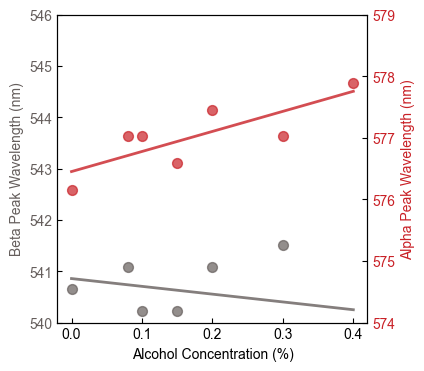

Peak Location Linear Regression Analysis:
Filtered data excludes concentrations: [0.02, 0.05]
Analyzing 7/9 concentrations

Beta Band (~542nm) Wavelength vs Concentration:
  Slope: -1.5185 nm/%
  R²: 0.082
  p-value: 0.5337

Alpha Band (~577nm) Wavelength vs Concentration:
  Slope: 3.2581 nm/%
  R²: 0.641
  p-value: 0.0306


In [132]:
# Plot peak location changes vs alcohol concentration with linear regression
# Apply the same exclusion logic as cell 15 (concentration-based exclusion)

# Apply exclusions to filter alcohol concentrations based on concentration values
exclude_concentrations = [0.02, 0.05]  # Same as cell 15
included_alcohol_indices = []
for i, concentration in enumerate(alcohol_concentrations):
    if concentration not in exclude_concentrations:
        included_alcohol_indices.append(i)

# Filter the data based on included indices
filtered_concentrations = [alcohol_concentrations[i] for i in included_alcohol_indices]
filtered_beta_peaks = [beta_peaks[i] for i in included_alcohol_indices]
filtered_alpha_peaks = [alpha_peaks[i] for i in included_alcohol_indices]

# Extract wavelength data for plotting
beta_wavelengths = [peak['wavelength'] for peak in filtered_beta_peaks]
alpha_wavelengths = [peak['wavelength'] for peak in filtered_alpha_peaks]

# Import scipy for linear regression
from scipy import stats

fig, ax1 = plt.subplots(figsize=(4, 4))

# Plot beta band wavelength vs concentration
ax1.scatter(filtered_concentrations, beta_wavelengths, color='#655e5c', s=50, alpha=0.7, label='Beta (~542nm)')

# Add linear regression for beta band
if len(filtered_concentrations) > 1:
    slope_beta, intercept_beta, r_beta, p_beta, stderr_beta = stats.linregress(filtered_concentrations, beta_wavelengths)
    x_fit = np.array(filtered_concentrations)
    y_fit_beta = slope_beta * x_fit + intercept_beta
    ax1.plot(x_fit, y_fit_beta, '#655e5c', alpha=0.8, linewidth=2)

ax1.set_position(pos_ax)

# Create twin y-axis for alpha band
ax2 = ax1.twinx()

# Plot alpha band wavelength vs concentration
ax2.scatter(filtered_concentrations, alpha_wavelengths, color='#c92127', s=50, alpha=0.7, label='Alpha (~577nm)')

# Add linear regression for alpha band
if len(filtered_concentrations) > 1:
    slope_alpha, intercept_alpha, r_alpha, p_alpha, stderr_alpha = stats.linregress(filtered_concentrations, alpha_wavelengths)
    y_fit_alpha = slope_alpha * x_fit + intercept_alpha
    ax2.plot(x_fit, y_fit_alpha, '#c92127', alpha=0.8, linewidth=2)

# Formatting
ax1.set_xlabel('Alcohol Concentration (%)')
ax1.set_ylabel('Beta Peak Wavelength (nm)', color='#655e5c')
ax2.set_ylabel('Alpha Peak Wavelength (nm)', color='#c92127')
ax1.tick_params(axis='y', labelcolor='#655e5c', direction='in')
ax2.tick_params(axis='y', labelcolor='#c92127', direction='in')
ax1.tick_params(axis='x', direction='in')

# Set y-axis limits to prevent overlapping
ax1.set_ylim(540, 546)  # Beta band range
ax2.set_ylim(574, 579)  # Alpha band range

# Set colors for y-axis labels
ax1.yaxis.label.set_color('#655e5c')
ax2.yaxis.label.set_color('#c92127')

plt.savefig('../figures/fig2/blood_alcohol_peak_trends_with_spectra_new.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# Print linear regression analysis results
print("Peak Location Linear Regression Analysis:")
print("=" * 50)
print(f"Filtered data excludes concentrations: {exclude_concentrations}")
print(f"Analyzing {len(filtered_concentrations)}/{len(alcohol_concentrations)} concentrations")
print()
print("Beta Band (~542nm) Wavelength vs Concentration:")
print(f"  Slope: {slope_beta:.4f} nm/%")
print(f"  R²: {r_beta**2:.3f}")
print(f"  p-value: {p_beta:.4f}")
print()
print("Alpha Band (~577nm) Wavelength vs Concentration:")
print(f"  Slope: {slope_alpha:.4f} nm/%")
print(f"  R²: {r_alpha**2:.3f}")
print(f"  p-value: {p_alpha:.4f}")

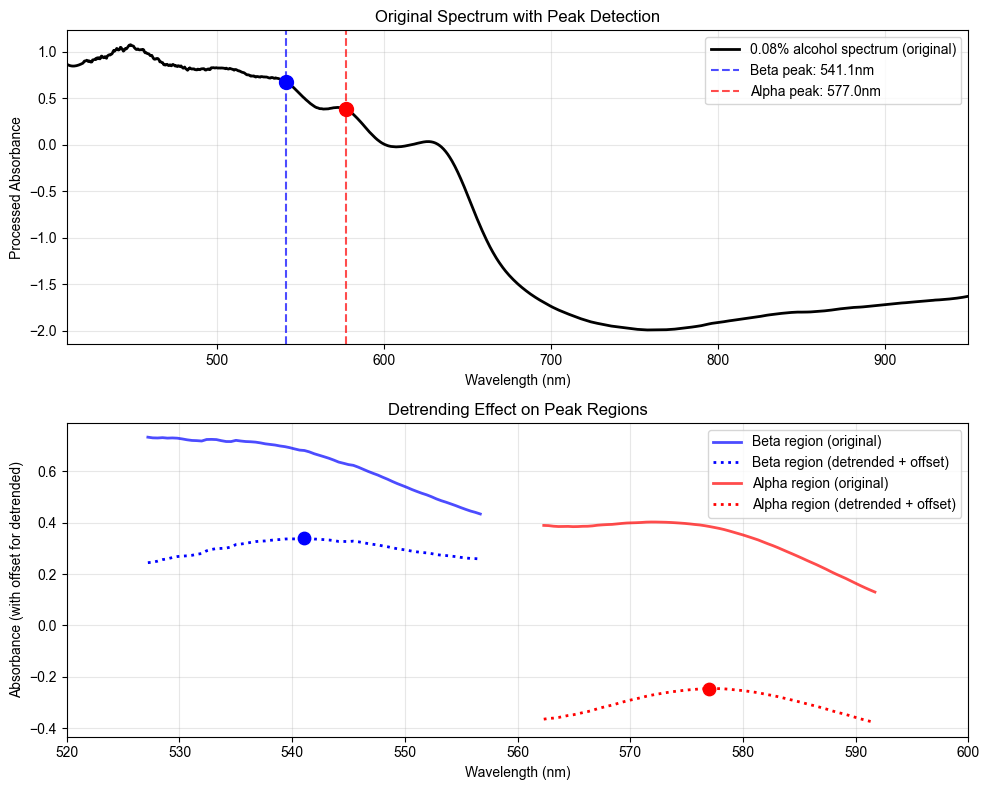

Comparison showing:
- Top plot: Original spectrum with detected peaks
- Bottom plot: Original vs detrended data in peak regions
- Detrended data (dotted lines) shows clearer peak definition
- Circles mark peaks found in detrended data


In [109]:
# Show peak locations and detrending effect on an example spectrum (KISS approach)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# Use 0.08% alcohol spectrum as example
example_idx = concentrations.index(0.08)
example_spectrum = S_emsc[example_idx]

# Get the detected peaks
beta_peak = beta_peaks[example_idx]
alpha_peak = alpha_peaks[example_idx]

# Plot 1: Original spectrum with peak detection
ax1.plot(w, example_spectrum, 'k-', linewidth=2, label='0.08% alcohol spectrum (original)')

# Mark the detected peaks
ax1.axvline(beta_peak['wavelength'], color='blue', linestyle='--', alpha=0.7, label=f"Beta peak: {beta_peak['wavelength']:.1f}nm")
ax1.axvline(alpha_peak['wavelength'], color='red', linestyle='--', alpha=0.7, label=f"Alpha peak: {alpha_peak['wavelength']:.1f}nm")

ax1.scatter(beta_peak['wavelength'], beta_peak['intensity'], color='blue', s=100, zorder=5)
ax1.scatter(alpha_peak['wavelength'], alpha_peak['intensity'], color='red', s=100, zorder=5)

ax1.set_xlabel('Wavelength (nm)')
ax1.set_ylabel('Processed Absorbance')
ax1.set_title('Original Spectrum with Peak Detection')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_xlim(410, 950)

# Plot 2: Show detrended regions around peaks
target_bands = [542, 577]  # Beta and Alpha bands
search_window = 15

for i, (target_wl, color, band_name) in enumerate(zip(target_bands, ['blue', 'red'], ['Beta', 'Alpha'])):
    # Define search window around target wavelength
    window_mask = (w >= target_wl - search_window) & (w <= target_wl + search_window)
    
    if np.any(window_mask):
        # Extract window data
        window_wl = w[window_mask]
        window_spectrum = example_spectrum[window_mask]
        
        # Detrend the spectrum
        window_spectrum_detrended = detrend(window_spectrum, type='linear')
        
        # Plot original window data
        ax2.plot(window_wl, window_spectrum, color=color, linewidth=2, alpha=0.7, 
                label=f'{band_name} region (original)')
        
        # Plot detrended window data (offset for clarity)
        offset = 0.3 if i == 0 else -0.3  # Different offsets for beta and alpha
        ax2.plot(window_wl, window_spectrum_detrended + offset, color=color, linewidth=2, 
                linestyle=':', label=f'{band_name} region (detrended + offset)')
        
        # Find peaks in detrended data
        peaks_det, _ = find_peaks(window_spectrum_detrended, height=None, prominence=0.01)
        
        if len(peaks_det) > 0:
            # Mark peaks found in detrended data
            for peak_idx in peaks_det:
                ax2.scatter(window_wl[peak_idx], window_spectrum_detrended[peak_idx] + offset, 
                           color=color, s=80, marker='o', zorder=5)

ax2.set_xlabel('Wavelength (nm)')
ax2.set_ylabel('Absorbance (with offset for detrended)')
ax2.set_title('Detrending Effect on Peak Regions')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_xlim(520, 600)  # Focus on the peak regions

plt.tight_layout()
plt.show()

print("Comparison showing:")
print("- Top plot: Original spectrum with detected peaks")
print("- Bottom plot: Original vs detrended data in peak regions")
print("- Detrended data (dotted lines) shows clearer peak definition")
print("- Circles mark peaks found in detrended data")

## visualization

### load from the spectra data

In [26]:
# example_spectrum_data = pd.read_csv('../figures/fig2/displayed_spectra_data.csv')
# alcohol_spectra = example_spectrum_data[['wavelength', '0.08%_alcohol']]
# acetaldehyde_spectra = example_spectrum_data[['wavelength', '0.40%_acetaldehyde_avg']]

In [27]:
# from scipy import stats

# fig = plt.figure(figsize=(4, 4))
# gs = fig.add_gridspec(2, 2, width_ratios=[3, 0.3], height_ratios=[1, 1], 
#                       hspace=0.3, wspace=0.01)

# # Main scatter plot (left side)
# ax_main = fig.add_subplot(gs[:, 0])

# # Get the last three columns (relative measurements)
# relative_cols = peak_analysis_df.columns[-3:]  # ['alpha_rel_to_0.00BAC', 'beta_rel_to_0.00BAC', 'A630_rel_to_0.00BAC']

# # Separate alcohol and acetaldehyde data
# alcohol_mask = peak_analysis_df['series'] == 'alcohol'
# acetaldehyde_mask = peak_analysis_df['series'] == 'acetaldehyde'

# # Use only the second half of the colormaps (darker, more saturated colors)
# alcohol_colors = Colormap('cmocean:matter')(np.linspace(0.2, 0.7, 3))
# acetaldehyde_colors = Colormap('cmocean:ice')(np.linspace(0.2, 0.7, 3))

# # Y-offset for acetaldehyde data to differentiate from alcohol
# acetaldehyde_y_offset = 0.5

# # Plot all data on the main axis
# for i, col in enumerate(relative_cols):
#     # Plot alcohol data
#     alcohol_data = peak_analysis_df[alcohol_mask]
#     if len(alcohol_data) > 0:
#         ax_main.scatter(alcohol_data['concentration_%'], alcohol_data[col], 
#                        color=alcohol_colors[i], 
#                        label=f'Alcohol - {col.replace("_", " ").replace("rel to 0.00BAC", "").strip()}',
#                        alpha=0.8, s=50, marker='o')
        
#         # Add trend line for alcohol data
#         if len(alcohol_data) > 1:
#             x_alc = alcohol_data['concentration_%'].values
#             y_alc = alcohol_data[col].values
#             slope, intercept, r_value, p_value, std_err = stats.linregress(x_alc, y_alc)
            
#             # Create smooth trend line
#             x_trend = np.linspace(x_alc.min(), x_alc.max(), 100)
#             y_trend = slope * x_trend + intercept
            
#             ax_main.plot(x_trend, y_trend, color=alcohol_colors[i], 
#                         linestyle='--', alpha=0.9, linewidth=1.5)
    
#     # Plot acetaldehyde data with y-offset
#     acetaldehyde_data = peak_analysis_df[acetaldehyde_mask]
#     if len(acetaldehyde_data) > 0:
#         ax_main.scatter(acetaldehyde_data['concentration_%'], 
#                        acetaldehyde_data[col] + acetaldehyde_y_offset, 
#                        color=acetaldehyde_colors[i], 
#                        label=f'Acetaldehyde - {col.replace("_", " ").replace("rel to 0.00BAC", "").strip()}',
#                        alpha=0.8, s=50, marker='s')
        
#         # Add trend line for acetaldehyde data
#         if len(acetaldehyde_data) > 1:
#             x_acet = acetaldehyde_data['concentration_%'].values
#             y_acet = acetaldehyde_data[col].values
#             slope, intercept, r_value, p_value, std_err = stats.linregress(x_acet, y_acet)
            
#             # Create smooth trend line
#             x_trend = np.linspace(x_acet.min(), x_acet.max(), 100)
#             y_trend = slope * x_trend + intercept + acetaldehyde_y_offset
            
#             ax_main.plot(x_trend, y_trend, color=acetaldehyde_colors[i], 
#                         linestyle='--', alpha=0.9, linewidth=1.5)

# # Set up clean y-axis with only 1.00 ticks for both scales
# alcohol_tick = 1.0
# acetaldehyde_tick = 1.0 + acetaldehyde_y_offset
# ax_main.set_yticks([alcohol_tick, acetaldehyde_tick])
# ax_main.set_yticklabels(['1', '1'])

# ax_main.set_xlabel('Concentration (%)')
# ax_main.set_ylabel('Relative Peak Value', labelpad=0)
# ax_main.tick_params(direction='in')
# # ax_main.legend()

# # Define peak positions and their corresponding colors
# peak_positions = [575, 540, 630]  # Alpha, Beta, A630
# alcohol_peak_colors = [alcohol_colors[0], alcohol_colors[1], alcohol_colors[2]]  # For alcohol spectrum
# acetaldehyde_peak_colors = [acetaldehyde_colors[0], acetaldehyde_colors[1], acetaldehyde_colors[2]]  # For acetaldehyde spectrum

# # Right side marginal plots - Acetaldehyde spectrum (top)
# ax_acetaldehyde = fig.add_subplot(gs[0, 1])
# ax_acetaldehyde.plot(acetaldehyde_spectra['0.40%_acetaldehyde_avg'], acetaldehyde_spectra['wavelength'], 
#                      color='gray', linewidth=1.5)

# # Add peak position markers for acetaldehyde spectrum (using blue colors)
# for peak_pos, peak_color in zip(peak_positions, acetaldehyde_peak_colors):
#     ax_acetaldehyde.axhline(y=peak_pos, color=peak_color, linestyle='-', linewidth=2, alpha=0.8)

# ax_acetaldehyde.set_xticks([])
# ax_acetaldehyde.set_yticks([])
# ax_acetaldehyde.set_ylim(410, 950)
# ax_acetaldehyde.tick_params(length=0)
# # Remove spines
# ax_acetaldehyde.spines['top'].set_visible(False)
# ax_acetaldehyde.spines['right'].set_visible(False)
# ax_acetaldehyde.spines['left'].set_visible(False)
# ax_acetaldehyde.spines['bottom'].set_visible(False)

# # Right side marginal plots - Alcohol spectrum (bottom)
# ax_alcohol = fig.add_subplot(gs[1, 1])
# ax_alcohol.plot(alcohol_spectra['0.08%_alcohol'], alcohol_spectra['wavelength'], 
#                 color='gray', linewidth=1.5)

# # Add peak position markers for alcohol spectrum (using alcohol colors)
# for peak_pos, peak_color in zip(peak_positions, alcohol_peak_colors):
#     ax_alcohol.axhline(y=peak_pos, color=peak_color, linestyle='-', linewidth=2, alpha=0.8)

# ax_alcohol.set_xticks([])
# ax_alcohol.set_yticks([])
# ax_alcohol.set_ylim(410, 950)
# ax_alcohol.tick_params(length=0)
# # Remove spines
# ax_alcohol.spines['top'].set_visible(False)
# ax_alcohol.spines['right'].set_visible(False)
# ax_alcohol.spines['left'].set_visible(False)
# ax_alcohol.spines['bottom'].set_visible(False)

# pos_ax_main = deepcopy(pos_ax)
# pos_ax_main.x1 -= 0.1
# ax_main.set_position(pos_ax_main)
# plt.savefig('../figures/fig2/blood_alcohol_acetaldehyde_peak_trends_with_spectra.svg', dpi=600, bbox_inches='tight', transparent=True)
# plt.show()

# For Fig S5

Loaded data for concentrations: [0.0, 0.1]
  0.00% BAC: 5 repetitions
  0.10% BAC: 5 repetitions


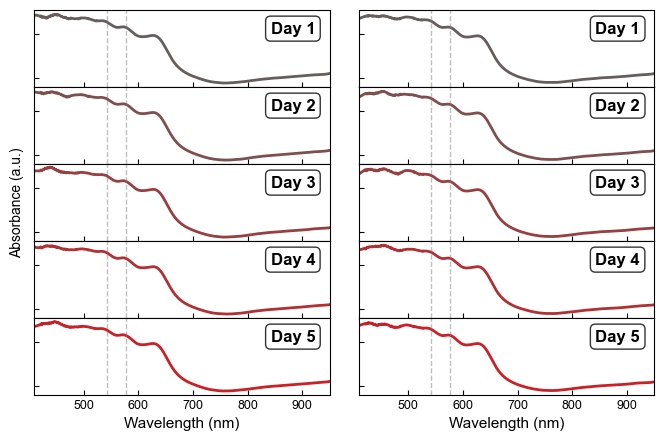

In [52]:
# Load and process individual repetitions for 0.00% and 0.10% BAC
alcohol_data_dir = '../data/blood_alcohol_spectra_2/'

# Define target concentrations and get their files
target_concentrations = [0.00, 0.10]
concentration_files = {
    0.00: [f'0_00_alc_3size_20scans_8ms_opt_{i}.csv' for i in range(1, 6)],
    0.10: [f'0_10_alc_3size_20scans_8ms_opt_{i}.csv' for i in range(1, 6)]
}

# Load and preprocess all individual files
processed_individual_data = {}
for concentration in target_concentrations:
    processed_individual_data[concentration] = []
    files = concentration_files[concentration]
    for i, file in enumerate(files):
        # Load data
        data = pd.read_csv(os.path.join(alcohol_data_dir, file), skiprows=9, header=None, names=['wavelength', 'absorbance'])
        
        # Apply savgol filter to log absorbance (same as other processing)
        log_absorbance = np.log(data['absorbance'] + 1e-6)  # Avoid log(0)
        log_absorbance = savgol_filter(log_absorbance, window_length=93, polyorder=3)
        
        processed_individual_data[concentration].append({'wavelength': data['wavelength'], 'log_absorbance': log_absorbance})

print(f"Loaded data for concentrations: {list(processed_individual_data.keys())}")
for conc in processed_individual_data:
    print(f"  {conc:.2f}% BAC: {len(processed_individual_data[conc])} repetitions")

# Apply EMSC processing to all individual files
all_data = []
for conc in target_concentrations:
    all_data.extend(processed_individual_data[conc])

S_individual = np.vstack([d['log_absorbance'] for d in all_data])
w_individual = np.median(np.vstack([d['wavelength'] for d in all_data]), axis=0)

# Same wavelength filtering as before
keep = (w_individual >= 410) & (w_individual <= 950)
w_individual = w_individual[keep]
S_individual = S_individual[:, keep]
r_individual = np.median(S_individual, axis=0)

# EMSC processing
X_individual = np.vstack([np.ones_like(w_individual), w_individual, w_individual**2, r_individual]).T
XtX_inv_individual = np.linalg.pinv(X_individual.T @ X_individual)
Xt_individual = X_individual.T

S_emsc_individual = np.empty_like(S_individual)
for i, s in enumerate(S_individual):
    a = XtX_inv_individual @ Xt_individual @ s
    S_emsc_individual[i] = (s - (a[0] + a[1]*w_individual + a[2]*w_individual**2)) / (a[3] if a[3]!=0 else 1.0)

# Reorganize processed data back into concentration groups
processed_emsc = {}
idx = 0
for conc in target_concentrations:
    num_reps = len(processed_individual_data[conc])
    processed_emsc[conc] = S_emsc_individual[idx:idx+num_reps]
    idx += num_reps

# Create (5, 2) subplot layout
fig, axes = plt.subplots(5, 2, figsize=(8, 5), sharex=True, sharey=True)

# Define 5 colors for the 5 repetitions (rows)
cm = Colormap(['#655e5c', '#c92127'])
row_colors = cm(np.linspace(0, 1, 5))

# Plot each repetition (row) for each concentration (column)
for col_idx, concentration in enumerate(concentrations_list):
    for rep_idx in range(5):  # 5 repetitions
        ax = axes[rep_idx, col_idx]
        
        # Get the spectrum for this repetition
        spectrum = processed_emsc[concentration][rep_idx]
        color = row_colors[rep_idx]
        
        # Plot the spectrum
        ax.plot(w_individual, spectrum, color=color, linewidth=2)
        
        # Add reference lines at hemoglobin peaks
        ax.axvline(x=542, color='gray', linestyle='--', linewidth=1, alpha=0.5)
        ax.axvline(x=577, color='gray', linestyle='--', linewidth=1, alpha=0.5)
        
        # Set y-axis label only for middle row (row 3) of leftmost column
        if col_idx == 0 and rep_idx == 2:  # Middle row (0-indexed, so row 2 is the 3rd row)
            ax.set_ylabel('Absorbance (a.u.)', fontsize=10)
        
        # Add day label inside each subplot
        ax.text(0.8, 0.85, f'Day {rep_idx+1}', transform=ax.transAxes, 
                fontsize=12, fontweight='bold', va='top', ha='left',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
        
        # Configure axes
        ax.set_xlim(410, 950)
        ax.tick_params(direction='in', labelsize=9)
        
        # Remove y-tick labels for right column to reduce clutter
        if col_idx == 1:
            ax.set_yticklabels([])

# Set x-axis label only for bottom row
for col_idx in range(2):
    axes[-1, col_idx].set_xlabel('Wavelength (nm)', fontsize=11)

from matplotlib.transforms import Bbox
pos_ax_topleft = axes[0, 0].get_position()
pos_ax_bottomright = axes[-1, 1].get_position()
pos_ax = Bbox.from_extents(pos_ax_topleft.x0, pos_ax_topleft.y0, pos_ax_bottomright.x1, pos_ax_bottomright.y1)

# Adjust layout
plt.subplots_adjust(hspace=0, wspace=0.1)
plt.savefig('../figures/SI/figs5-spectra_over_time/blood_alcohol_individual_repetitions_subplot_0.00_0.10.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

In [53]:
pos_ax_topleft, pos_ax_bottomright

(Bbox([[0.125, 0.7472413793103448], [0.47727272727272724, 0.88]]),
 Bbox([[0.5477272727272726, 0.10999999999999999], [0.8999999999999999, 0.24275862068965515]]))

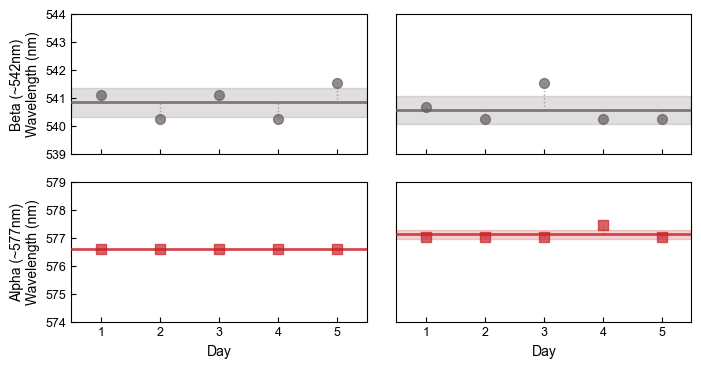


Peak Wavelength Statistical Analysis:

0.00% BAC:
  Beta Band (~542nm):
    Mean: 540.826 nm
    Std Dev: 0.521 nm
    CV: 0.10%
  Alpha Band (~577nm):
    Mean: 576.592 nm
    Std Dev: 0.000 nm
    CV: 0.00%

0.10% BAC:
  Beta Band (~542nm):
    Mean: 540.566 nm
    Std Dev: 0.506 nm
    CV: 0.09%
  Alpha Band (~577nm):
    Mean: 577.110 nm
    Std Dev: 0.173 nm
    CV: 0.03%


In [55]:
# Analyze peaks for individual repetitions over time for each concentration
from scipy.signal import find_peaks, detrend
from scipy import stats

def find_spectral_peaks_individual(wavelength, spectrum, target_wavelengths, search_window=20):
    """Find peaks for individual spectra - same as before but for clarity"""
    peak_info = {}
    
    for target_wl in target_wavelengths:
        window_mask = (wavelength >= target_wl - search_window) & (wavelength <= target_wl + search_window)
        
        if not np.any(window_mask):
            peak_info[target_wl] = {'wavelength': np.nan, 'intensity': np.nan}
            continue
            
        window_wl = wavelength[window_mask]
        window_spectrum = spectrum[window_mask]
        
        window_spectrum_detrended = detrend(window_spectrum, type='linear')
        peaks, properties = find_peaks(window_spectrum_detrended, height=None, prominence=0.01)
        
        if len(peaks) == 0:
            max_idx = np.argmax(window_spectrum_detrended)
            peak_wl = window_wl[max_idx]
            peak_intensity = window_spectrum[max_idx]
        else:
            peak_wavelengths = window_wl[peaks]
            distances = np.abs(peak_wavelengths - target_wl)
            closest_peak_idx = peaks[np.argmin(distances)]
            
            peak_wl = window_wl[closest_peak_idx]
            peak_intensity = window_spectrum[closest_peak_idx]
        
        peak_info[target_wl] = {
            'wavelength': peak_wl,
            'intensity': peak_intensity
        }
    
    return peak_info

# Extract peak data for both concentrations over 5 days
days = np.arange(1, 6)  # Days 1-5
concentrations_list = [0.00, 0.10]

peak_data_over_time = {}
for concentration in concentrations_list:
    beta_peaks_time = []
    alpha_peaks_time = []
    
    for day_idx in range(5):
        spectrum = processed_emsc[concentration][day_idx]
        peaks = find_spectral_peaks_individual(w_individual, spectrum, [542, 577], search_window=15)
        
        beta_peaks_time.append(peaks[542]['wavelength'])
        alpha_peaks_time.append(peaks[577]['wavelength'])
    
    peak_data_over_time[concentration] = {
        'beta': beta_peaks_time,
        'alpha': alpha_peaks_time
    }

# Create (2, 2) subplot layout: rows for beta/alpha, columns for concentrations
fig, axes = plt.subplots(2, 2, figsize=(8, 4), sharex=True)

# Colors for different peaks
peak_colors = {'beta': '#655e5c', 'alpha': '#c92127'}

# Column and row titles
col_titles = ['0.00% BAC', '0.10% BAC']
row_titles = ['Beta (~542nm)', 'Alpha (~577nm)']

# Plot each concentration and peak type in separate subplots
for col_idx, concentration in enumerate(concentrations_list):
    for row_idx, peak_type in enumerate(['beta', 'alpha']):
        ax = axes[row_idx, col_idx]
        
        # Get data for this concentration and peak type
        peak_data = np.array(peak_data_over_time[concentration][peak_type])
        
        # Calculate statistics
        peak_mean = np.mean(peak_data)
        peak_std = np.std(peak_data)
        
        # Plot peaks
        marker = 'o' if peak_type == 'beta' else 's'
        ax.scatter(days, peak_data, color=peak_colors[peak_type], s=50, alpha=0.7, 
                   marker=marker, label=row_titles[row_idx], zorder=5)
        
        # Draw horizontal mean line and std area
        ax.axhline(y=peak_mean, color=peak_colors[peak_type], linestyle='-', linewidth=2, alpha=0.8, zorder=3)
        ax.fill_between([0.5, 5.5], peak_mean - peak_std, peak_mean + peak_std, 
                        color=peak_colors[peak_type], alpha=0.2, zorder=1)
        
        # Connect each point to mean line
        for day, peak_val in zip(days, peak_data):
            ax.plot([day, day], [peak_val, peak_mean], color=peak_colors[peak_type], 
                    linestyle=':', alpha=0.5, linewidth=1, zorder=2)
        
        if col_idx == 0:  # Left column
            ax.set_ylabel(f'{row_titles[row_idx]}\nWavelength (nm)', fontsize=10)
        else:
            ax.set_yticks([])  # Remove y-tick labels for right column
        if row_idx == 1:  # Bottom row
            ax.set_xlabel('Day', fontsize=10)
        
        # Set appropriate y-limits for each peak type
        if peak_type == 'beta':
            ax.set_ylim(539, 544)  # Beta peak range
        else:
            ax.set_ylim(574, 579)  # Alpha peak range
        
        ax.tick_params(direction='in', labelsize=9)
        ax.set_xlim(0.5, 5.5)
        ax.set_xticks(days)

plt.subplots_adjust(wspace=0.1)
plt.savefig('../figures/SI/figs5-spectra_over_time/peak_wavelength_time_trends_subplot.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# Print statistical analysis results
print("\nPeak Wavelength Statistical Analysis:")
print("=" * 50)
for i, concentration in enumerate(concentrations_list):
    beta_data = np.array(peak_data_over_time[concentration]['beta'])
    alpha_data = np.array(peak_data_over_time[concentration]['alpha'])
    
    # Calculate statistics
    beta_mean = np.mean(beta_data)
    beta_std = np.std(beta_data)
    beta_cv = (beta_std / beta_mean) * 100  # Coefficient of variation
    
    alpha_mean = np.mean(alpha_data)
    alpha_std = np.std(alpha_data)
    alpha_cv = (alpha_std / alpha_mean) * 100
    
    print(f"\n{concentration:.2f}% BAC:")
    print(f"  Beta Band (~542nm):")
    print(f"    Mean: {beta_mean:.3f} nm")
    print(f"    Std Dev: {beta_std:.3f} nm")
    print(f"    CV: {beta_cv:.2f}%")
    print(f"  Alpha Band (~577nm):")
    print(f"    Mean: {alpha_mean:.3f} nm")
    print(f"    Std Dev: {alpha_std:.3f} nm") 
    print(f"    CV: {alpha_cv:.2f}%")

# For Fig1

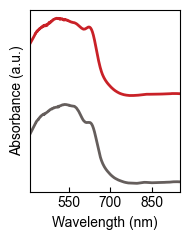

In [12]:
files = ['../data/blood_alcohol_spectra/0_00_alc_slide.csv',
         '../data/blood_alcohol_spectra/0_40_alc_slide.csv']

# Load and preprocess all data before plotting
processed_data = []
for file in files:
    data = pd.read_csv(file, skiprows=9, header=None, names=['wavelength', 'absorbance'])
    log_absorbance = np.log(data['absorbance'] + 1e-6)  # Avoid log(0)
    log_absorbance = savgol_filter(log_absorbance, window_length=121, polyorder=2)
    processed_data.append({'wavelength': data['wavelength'], 'log_absorbance': log_absorbance})

# find the wavelength array and the absorbance array of the median spectrum
S = np.vstack([d['log_absorbance'] for d in processed_data])                    # [N, L]
w = np.median(np.vstack([d['wavelength'] for d in processed_data]), axis=0)     # [L]

keep = (w >= 410) & (w <= 950)
w = w[keep]
S = S[:, keep]
r = np.median(S, axis=0)

X = np.vstack([np.ones_like(w), w, w**2, r]).T      # [L, 4]
XtX_inv = np.linalg.pinv(X.T @ X)                   # precompute for efficiency
Xt = X.T

S_emsc = np.empty_like(S)
for i, s in enumerate(S):
    a = XtX_inv @ Xt @ s
    S_emsc[i] = (s - (a[0] + a[1]*w + a[2]*w**2)) / (a[3] if a[3]!=0 else 1.0)

cm = Colormap(['#655e5c', '#c92127'])
# cm = Colormap('observable:observable10')
colors = cm(np.linspace(0, 1, len(files)))

y_offset = 2.0

plt.figure(figsize=(2, 2.5))

for i, (s, concentration) in enumerate(zip(S_emsc, alcohol_concentrations)):
    color = colors[i % len(colors)]
    plt.plot(w, s + i * y_offset, 
             color=color, linewidth=2, 
             label=f'{concentration:.2f}% alcohol')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Absorbance (a.u.)')
plt.xticks(np.arange(400, 1000, 150))
plt.yticks([])

plt.xlim(410, 950)
# plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tick_params(direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig1/example_blood_alcohol_spectra.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()